# Plot signatures

This notebook generates some static plots of spatial signatures. We have a series of custom MapBox basemaps that need an API token. You will need to create and pass your own token to reproduce the figures.

## Spatial Signatures

In [1]:
import geopandas as gpd
from shapely.geometry import Point
import urbangrammar_graphics as ugg
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.lines import Line2D
import contextily

In [2]:
sns.set(context="paper", style="ticks", rc={'patch.force_edgecolor': False})

In [3]:
spsig = gpd.read_file("spatial_signatures_GB.gpkg")

In [4]:
spsig

,id,code,type,geometry
0,0_COA,COA,Countryside agriculture,"POLYGON ((62220.000 798500.000, 62110.000 7985..."
1,1_COA,COA,Countryside agriculture,"POLYGON ((63507.682 796515.169, 63471.097 7965..."
2,2_COA,COA,Countryside agriculture,"POLYGON ((65953.174 802246.172, 65950.620 8022..."
3,3_COA,COA,Countryside agriculture,"POLYGON ((67297.740 803435.800, 67220.289 8034..."
4,4_COA,COA,Countryside agriculture,"POLYGON ((75760.000 852670.000, 75700.000 8527..."
...,...,...,...,...
96699,96699_OUT,OUT,outlier,"POLYGON ((323321.005 463795.416, 323319.842 46..."
96700,96700_OUT,OUT,outlier,"POLYGON ((325929.840 1008792.061, 325927.377 1..."
96701,96701_OUT,OUT,outlier,"POLYGON ((337804.770 1013422.583, 337800.122 1..."
96702,96702_OUT,OUT,outlier,"POLYGON ((422304.270 1147826.990, 422296.000 1..."


In [5]:
cmap = ugg.get_colormap(24, randomize=False)

In [6]:
cols = cmap.colors

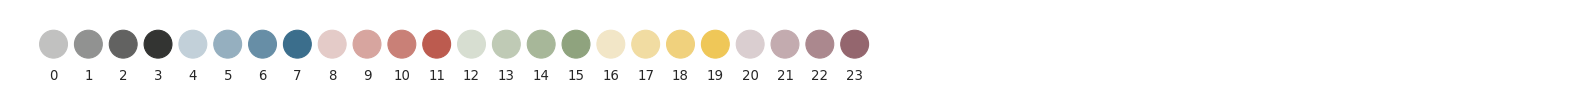

In [7]:
fig, ax = plt.subplots(figsize=(20, 5))
for i, c in enumerate(cols):
    ax.add_artist(plt.Circle((i, 0), 0.4, color=c))
    plt.text(i, -1, i, horizontalalignment='center')
    ax.set_axis_off()
    ax.set_aspect(1)
    ax.autoscale()
    plt.xlim(-1.25,43.25)
    plt.ylim(-1,1)

In [8]:
types = {
    0: "Countryside agriculture",
    1: "Accessible suburbia",
    3: "Open sprawl",
    4: "Wild countryside",
    5: "Warehouse/Park land",
    6: "Gridded residential quarters",
    7: "Urban buffer",
    8: "Disconnected suburbia",
    20: "Dense residential neighbourhoods",
    21: "Connected residential neighbourhoods",
    22: "Dense urban neighbourhoods",
    90: "Local urbanity",
    91: "Concentrated urbanity",
    92: "Regional urbanity",
    94: "Metropolitan urbanity",
    95: "Hyper concentrated urbanity",
    93: "outlier",
    96: "outlier",
    97: "outlier",
    98: "outlier",
}

In [9]:
symbology = {'Countryside agriculture': cols[16],
             'Accessible suburbia': cols[15],
             'Open sprawl': cols[9],
             'Wild countryside': cols[12],
             'Warehouse/Park land': cols[21],
             'Gridded residential quarters': cols[8],
             'Urban buffer': cols[4],
             'Disconnected suburbia': cols[18],
             'Dense residential neighbourhoods': cols[6],
             'Connected residential neighbourhoods': cols[23],
             'Dense urban neighbourhoods': cols[19],
             'Local urbanity': cols[7],
             'Concentrated urbanity': cols[3],
             'Regional urbanity': cols[22],
             'Metropolitan urbanity': cols[11],
             'Hyper concentrated urbanity': cols[14],
             'outlier': cols[0], # outlier
            }

In [10]:
spsig = spsig.to_crs(3857)

In [11]:
token = "pk.eyJ1IjoibWFydGluZmxlaXMiLCJhIjoiY2t3Zzlkb3p4MGtrYzJvbnZqOGpjZjZtNSJ9.ANK4NEb_I45ucD_BHZt-Mg"

In [12]:
df = spsig

In [13]:
london = gpd.GeoSeries([Point(-0.10875602230396436, 51.50933674406198)], crs=4326).to_crs(3857).buffer(35000).total_bounds
birmingham = gpd.GeoSeries([Point(-1.9836323453459492, 52.51781818221639)], crs=4326).to_crs(3857).buffer(35000).total_bounds
belt = gpd.GeoSeries([Point(-3.8718635546837663, 55.89080727223461)], crs=4326).to_crs(3857).buffer(120000).total_bounds
tyne = gpd.GeoSeries([Point(-1.6062, 54.9684)], crs=4326).to_crs(3857).buffer(35000).total_bounds

places = [london, birmingham, belt, tyne]

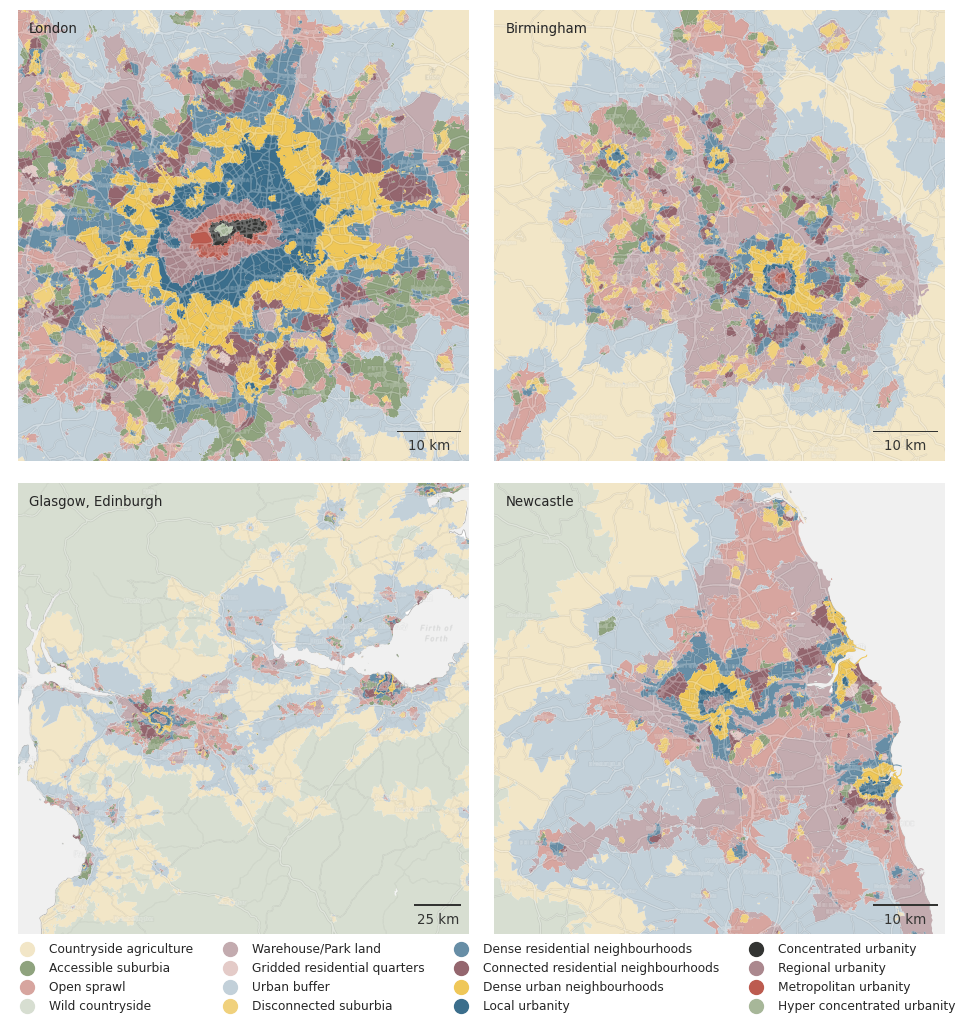

In [30]:
f, axs = plt.subplots(2, 2, figsize=(12, 12))

for place, ax in zip(places, axs.flat):
    ax = df.plot(color=df['type'].map(symbology), ax=ax, zorder=1, alpha=1)
    
    ax.set_xlim(place[0], place[2])
    ax.set_ylim(place[1], place[3])
    
    contextily.add_basemap(ax, crs=df.crs, attribution="", source=ugg.get_tiles('roads', token), zorder=2, alpha=.3)
    # contextily.add_basemap(ax, crs=df.crs, attribution="", source=ugg.get_tiles('labels', token), zorder=3, alpha=1)
    contextily.add_basemap(ax, crs=df.crs, attribution="", source=ugg.get_tiles('background', token), zorder=-1, alpha=1)
    ax.set_axis_off()
    
    scalebar = ScaleBar(dx=1,
                        color=ugg.COLORS[0],
                        location='lower right',
                        height_fraction=0.004,
                        pad=.5,
                        frameon=False,
                        )
    ax.add_artist(scalebar)

# ugg.north_arrow(plt.gcf(), ax, 0, size=.05, linewidth=1, color=ugg.COLORS[0], loc="upper left", pad=.002, alpha=.9)

custom_points = [Line2D([0], [0], marker="o", linestyle="none", markersize=10, color=color) for color in symbology.values()][:-1]
plt.legend(custom_points, list(symbology.keys())[:-1], bbox_to_anchor=(-0.02, -0.2), loc='lower center', frameon=False, ncols=4)
plt.subplots_adjust(wspace=.05, hspace=.05)
for name, ax in zip(["London", "Birmingham", "Glasgow, Edinburgh", "Newcastle"], axs.flat):
    ax.set_title(name, loc='left', zorder=10, y=.93, x=.025)
plt.savefig("subplots.png", dpi=300, bbox_inches="tight")